# 10. Support Vector Machine (SVM) Classification

## Lý thuyết & Nguyên lý

### 10.1. Siêu phẳng phân tách với lề tối đa (Max-Margin Separator)

SVM tìm siêu phẳng $w^\top x + b = 0$ **phân tách các lớp với khoảng cách lớn nhất** tới điểm dữ liệu gần nhất của mỗi lớp. Khoảng cách này gọi là **margin hình học**; các điểm sát mép lề gọi là **support vectors**.

Bài toán tối ưu:

$$\min_{w,b} \frac{1}{2}\|w\|^2 \qquad \text{không gian hóa:} \quad y_i\,(w^\top x_i + b) \ge 1 \;\; \forall i$$

Tối thiểu hóa $\frac{1}{2}\|w\|^2$ chính là **tối đa hóa lề** (vì margin $= 2/\|w\|$). Tính chất đẹp: chỉ **support vectors** quyết định siêu phẳng — bỏ các điểm khác không ảnh hưởng mô hình.

### 10.2. Soft Margin — dữ liệu không tách tuyến tính hoàn hảo

Dữ liệu thật hầu như luôn chồng lấn. SVM cho phép một số điểm **sai lầm** (sai phía lề hoặc sai bên) bằng biến slack $\xi_i$, đánh đổi bằng hệ số $C$:

$$\min_{w,b,\xi} \frac{1}{2}\|w\|^2 + C\sum_{i=1}^n \xi_i \qquad \text{s.t.} \quad y_i(w^\top x_i + b) \ge 1 - \xi_i,\;\; \xi_i \ge 0$$

- $C$ **lớn**: phạt nặng mọi vi phạm → lề hẹp, bám dữ liệu, dễ overfit (hard margin gần đúng).
- $C$ **nhỏ**: chấp nhận vi phạm để giữ lề rộng → tổng quát hóa tốt hơn (soft margin).

### 10.3. Kernel Trick — phân tách phi tuyến

Khi dữ liệu **không tách được bằng siêu phẳng**, SVM chiếu dữ liệu lên không gian đặc trưng cao hơn (implicit, không tính trực tiếp $\phi(x)$) bằng hàm kernel:

$$K(x, x') = \phi(x)^\top \phi(x')$$

- **Linear:** $K = x^\top x'$ — nhanh, dùng khi $p$ lớn, dữ liệu gần tuyến tính.
- **RBF (Gaussian):** $K = \exp(-\gamma\|x - x'\|^2)$ — mặc định mạnh nhất; mỗi điểm huấn luyện tạo một "gò" xác suất quanh nó.
- **Polynomial:** $K = (\gamma x^\top x' + r)^d$.

$\gamma$ lớn → vùng ảnh hưởng từng điểm hẹp (ranh giới gập ghềnh, dễ overfit); $\gamma$ nhỏ → hiệu ứng lan rộng (ranh giới mượt, dễ underfit).

### 10.4. Quy ước scikit-learn

- `decision_function(x)` trả về **khoảng cách có dấu** tới siêu phẳng (dương = lớp 1, âm = lớp 0); giá trị tuyệt đối càng lớn → mô hình càng tự tin.
- Số support vectors nằm trong `support_vectors_` — quan sát được trực tiếp.


Số support vectors: 2 / 50 mẫu


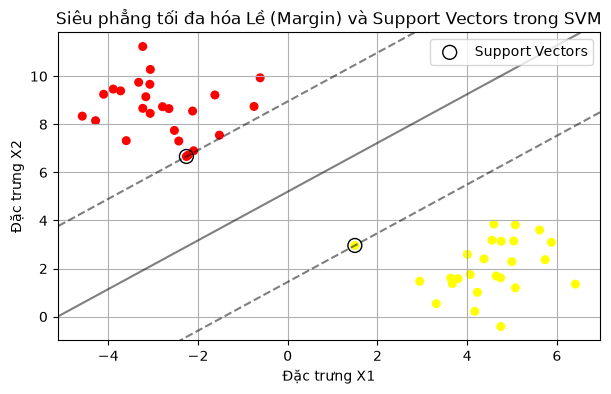

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

# 1. Tạo dữ liệu 2 lớp, 2 cụm, độ phân tán vừa phải (có thể chồng lấn)
X, y = make_blobs(n_samples=50, centers=2, cluster_std=1.2, random_state=42)
clf = SVC(kernel='linear', C=1000).fit(X, y)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap='autumn')

# 2. Vẽ siêu phẳng (z=0) và đường cách lề (z=±1)
ax = plt.gca()
xlim, ylim = ax.get_xlim(), ax.get_ylim()
xx, yy = np.meshgrid(
    np.linspace(xlim[0], xlim[1], 50),
    np.linspace(ylim[0], ylim[1], 50),
)
Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

ax.contour(
    xx,
    yy,
    Z,
    colors='k',
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=['--', '-', '--'],
)
ax.scatter(
    clf.support_vectors_[:, 0],
    clf.support_vectors_[:, 1],
    s=100,
    linewidth=1,
    facecolors='none',
    edgecolors='k',
    label='Support Vectors',
)
plt.title('Siêu phẳng tối đa hóa Lề (Margin) và Support Vectors trong SVM')
plt.xlabel('Đặc trưng X1')
plt.ylabel('Đặc trưng X2')
plt.legend()
plt.grid(True)
plt.show()

print(f"Số support vectors: {len(clf.support_)} / {len(X)} mẫu")


## Ý nghĩa của biểu đồ

- Đường **đứt nét mảnh hai bên** là mép trên/dưới của lề (hai đường $z = \pm 1$); **đường liền giữa** là siêu phẳng phân tách ($z = 0$).
- Các vòng tròn rỗng là **support vectors** — chỉ chúng "ghì" lề tại chỗ; các điểm khác (nằm sâu trong vùng của lớp mình) có thể bỏ đi mà siêu phẳng không đổi.
- $C = 1000$ (lớn) ép mô hình tìm siêu phẳng chia đúng hầu hết điểm → lề tương đối hẹp; giảm $C$ sẽ thấy lề được nới rộng và nhiều điểm hơn trở thành support vectors.

---

## Tổng quan mô hình

### Ưu điểm

- **Nguyên lý tối ưu hóa lề** giúp mô hình khái quát hóa tốt, đặc biệt với dữ liệu **vừa và nhỏ, số chiều cao** (chữ ký sinh học, văn bản, gen).
- **Kernel trick** xử lý phi tuyến mạnh mẽ, nhất là RBF — không cần tự engineer đặc trưng.
- **Ít nhạy outliers** nhờ soft margin (một số điểm sai được chấp nhận).
- **Robust với dữ liệu ít mẫu, nhiều chiều** — thường thắng Logistic Regression khi ranh giới phi tuyến và $n$ nhỏ.
- Hiệu quả bộ nhớ: mô hình chỉ lưu support vectors.

### Nhược điểm

- **Không tự chọn đặc trưng:** với dữ liệu bảng nhiều đặc trưng rác, thường thua Gradient Boosting.
- **Tuning nhiều tham số:** $C$, $\gamma$, kernel — cần GridSearchCV.
- **Chậm với dữ liệu rất lớn** (độ phức tạp tối ưu khoảng $O(n^2)$–$O(n^3)$).
- **Phải chuẩn hóa** đặc trưng (vì tính khoảng cách).
- **Dự đoán xác suất không trực tiếp** — cần `probability=True` (dùng Platt scaling, tăng chi phí huấn luyện) hoặc hiệu chỉnh bên ngoài.
- Khó diễn giải mô hình nội tại (đặc biệt khi dùng kernel phi tuyến).

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `C` | Đánh đổi lề rộng ↔ sai số cho phép | 0.01–1000, quét theo thang log |
| `gamma` | Phạm vi ảnh hưởng điểm (RBF/poly) | Thang log; mặc định `scale` = $1/(p\cdot\text{Var}(X))$ |
| `kernel` | 'linear', 'rbf', 'poly', 'sigmoid' | RBF mặc định; linear khi $p$ rất lớn |
| `degree` | Bậc của kernel polynomial | Chỉ dùng khi `kernel='poly'` |
| `class_weight` | Cân bằng lớp | 'balanced' khi dữ liệu lệch lớp |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Lớp ($Y$) |
| :--- | :--- | :--- | :--- |
| **NLP** | Phân loại email/tin nhắn | Bag-of-words / TF-IDF (chiều cao) | Spam / Không spam |
| **Y sinh** | Chẩn đoán từ hồ sơ gene | Vector biểu hiện gen (p >> n) | Bệnh / Khỏe |
| **Nhận dạng** | Nhận dạng chữ viết tay | Vector đặc trưng ảnh | Chữ số 0–9 |
| **Tài chính** | Phát hiện giao dịch gian lận | Đặc trưng giao dịch chuẩn hóa | Gian lận / Bình thường |
| **An ninh mạng** | Phân loại lưu lượng | Gói tin, cờ, thời lượng kết nối | Tấn công / Bình thường |

### Mẹo thực hành

- Dùng `Pipeline([('scaler', StandardScaler()), ('svc', SVC())])` + `GridSearchCV` quét `C` và `gamma` theo thang log $10^{-3}$ đến $10^{2}$.
- Với $p$ rất lớn (ngàn đặc trưng), thử `kernel='linear'` trước — nhanh hơn nhiều và thường không kém RBF.
- Muốn xác suất: `SVC(probability=True)` hoặc huấn luyện thêm Logistic Regression trên `decision_function` của SVM.


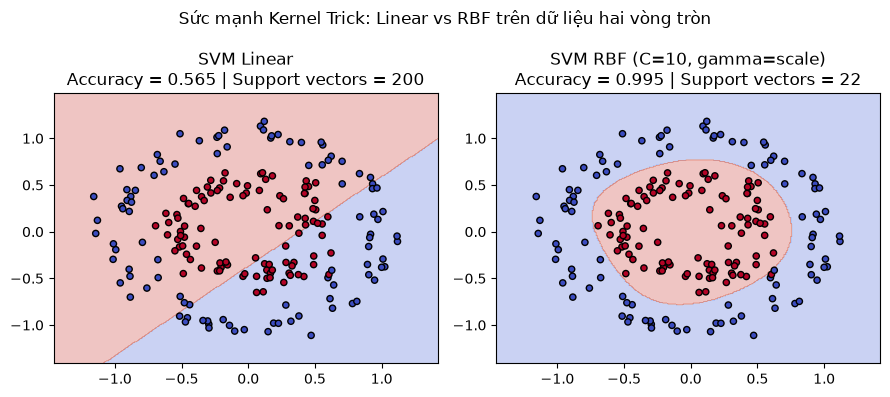

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_circles
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 1. Dữ liệu hai vòng tròn đồng tâm — KHÔNG phân tách tuyến tính
X, y = make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=42)

# 2. So sánh kernel Linear và RBF
models = {
    'SVM Linear': make_pipeline(StandardScaler(), SVC(kernel='linear', C=10)),
    'SVM RBF (C=10, gamma=scale)': make_pipeline(StandardScaler(), SVC(kernel='rbf', C=10, gamma='scale')),
}

xx, yy = np.meshgrid(
    np.linspace(X[:, 0].min() - 0.3, X[:, 0].max() + 0.3, 300),
    np.linspace(X[:, 1].min() - 0.3, X[:, 1].max() + 0.3, 300),
)
grid = np.c_[xx.ravel(), yy.ravel()]

plt.figure(figsize=(9, 4))
for i, (name, model) in enumerate(models.items(), 1):
    model.fit(X, y)
    acc = accuracy_score(y, model.predict(X))
    Z = model.predict(grid).reshape(xx.shape)
    n_sv = len(model[-1].support_)

    plt.subplot(1, 2, i)
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k', s=20)
    plt.title(f'{name}\nAccuracy = {acc:.3f} | Support vectors = {n_sv}')

plt.suptitle('Sức mạnh Kernel Trick: Linear vs RBF trên dữ liệu hai vòng tròn')
plt.tight_layout()
plt.show()


## Giải thích kết quả

- **SVM Linear:** chỉ vẽ được ranh giới **tuyến tính** (đường thẳng) giữa hai vòng tròn → gần như thất bại hoàn toàn (accuracy ~0.5–0.7).
- **SVM RBF:** kernel chiếu dữ liệu lên không gian đặc trưng sao cho hai vòng tròn trở nên **phân tách tuyến tính** — ranh giới sinh ra trong không gian gốc là **hai vòng tròn đồng tâm** (accuracy ≈ 1.0).
- Đây là minh họa điển hình cho **kernel trick**: mô hình vẫn "chỉ vẽ đường thẳng", nhưng trong không gian đã được chiếu — và ta trực quan hóa được hình chiếu về không gian gốc.

**Kết luận:** SVM là mô hình mạnh khi dữ liệu **ít mẫu, phi tuyến, nhiều chiều**; còn trên dữ liệu bảng khổ lớn, hãy cân nhắc Gradient Boosting/LightGBM thay thế.
